<a href="https://colab.research.google.com/github/k-nikhil-coder/100-day-ai-engineer/blob/main/Day_29_LLM_Mechanics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 29: Peeking Under the Hood — How LLMs Actually Process Text


**Phase:** Phase 2 — GenAI, RAG & Fine-Tuning  

---

### Why this day matters
Before jumping into LangChain, writing complex prompts, or wiring up agents, it's worth answering a very fundamental question: **what actually happens between me typing a prompt and the model spitting out an answer?**

When we talk to ChatGPT, Claude, or Gemini, it feels like they understand English. But under the hood:
1. They can't read words.
2. They don't output sentences.
3. They are simply massive matrix-multiplication engines predicting **what single integer token is statistically most likely to come next**.

In this notebook, I'm breaking down the math, the quirks, and the mechanics that every engineer needs to understand before building production RAG or fine-tuning pipelines.

## 0. Quick Setup
We'll need `tiktoken` (OpenAI's fast BPE tokenizer), `torch` for tensor operations, and `matplotlib` to plot how temperature actually alters probability.

In [1]:
!pip install -q tiktoken torch matplotlib
print("Ready to roll!")

Ready to roll!


---
## 1. Tokenization: Why LLMs Can't Count Letters

Ever wondered why models historically struggle with simple things like:  
*How many 'r's are in strawberry?* or *Reverse this string*?

It's not because the model is "dumb"—it's because of **how it sees text**.

- **Option A: Word-level?** Doesn't work. Dictionaries have millions of words. What about typos, slang, or code syntax like `foo_bar_v2`? The model's embedding matrix would explode.
- **Option B: Character-level?** Sounds clean, but sequences become ridiculously long. Transformers compute self-attention with $O(N^2)$ complexity relative to sequence length. A 500-word paragraph would become 3,000 characters, crushing memory and compute.
- **Option C: Subword Tokenization (Byte-Pair Encoding / BPE).** This is the sweet spot. Frequent words stay whole, rare words get chopped into sensible pieces, and everything maps to a fixed vocabulary table (roughly ~100k tokens in modern models).

In [2]:
import tiktoken

# Let's inspect the tokenizer used by GPT-4 / GPT-3.5
tokenizer = tiktoken.get_encoding("cl100k_base")
print(f"Vocabulary size: {tokenizer.n_vocab:,} unique tokens")

Vocabulary size: 100,277 unique tokens


### Let's test some real examples
Watch how the tokenizer slices different inputs. Notice what happens to numbers, code indentation, and leading spaces:

In [3]:
test_cases = [
    "Hello world!",
    "strawberry",                               # Watch how 'strawberry' gets split
    "apple",
    " apple",                                  # Notice how the leading space creates a totally different token ID!
    "1234567890",                               # Multi-digit numbers get fragmented
    "    def calculate_embeddings():",         # Python indentations consume dedicated tokens
]

print(f"{'String':<35} | {'Tokens':<6} | {'Subword Chunks'}")
print("-" * 75)

for text in test_cases:
    token_ids = tokenizer.encode(text)
    chunks = [tokenizer.decode_single_token_bytes(t).decode('utf-8', errors='replace') for t in token_ids]
    print(f"{text:<35} | {len(token_ids):<6} | {chunks}")

String                              | Tokens | Subword Chunks
---------------------------------------------------------------------------
Hello world!                        | 3      | ['Hello', ' world', '!']
strawberry                          | 3      | ['str', 'aw', 'berry']
apple                               | 1      | ['apple']
 apple                              | 1      | [' apple']
1234567890                          | 4      | ['123', '456', '789', '0']
    def calculate_embeddings():     | 5      | ['   ', ' def', ' calculate', '_embeddings', '():']


**Key takeaways from the test:**
1. `"strawberry"` is split into chunks like `['str', 'aw', 'berry']`. The model literally never sees the individual letters `s-t-r-a-w-b-e-r-r-y` unless you force it to spell them out!
2. `"apple"` (ID 1749) and `" apple"` with a space (ID 12903) are **completely different integers** in the model's eyes. Trailing spaces in prompts matter a lot.
3. Numbers are chopped unevenly, which explains why LLMs struggle with multi-digit column addition without scratchpads (Chain of Thought).

---
## 2. The Next-Token Engine: Logits $\to$ Softmax $\to$ Temperature

When the model finishes processing all your input tokens through its transformer layers, what comes out at the very end?

A giant list of unnormalized numbers called **logits**—one raw score for every single token in the vocabulary (~100,000 values).

To turn these raw scores into actual percentages (probabilities that add up to 100%), we pass them through **Softmax**:

$$P(token_i) = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

Where $T$ is **Temperature**:
- **$T = 0.1$ (Low):** We divide logits by a tiny number, which dramatically exaggerates the difference. The top choice becomes practically 99%+ likely. Great for JSON schemas, SQL queries, and deterministic code.
- **$T = 0.7$ (Balanced):** The default sweet spot. Coherent, but has enough variety to sound natural.
- **$T = 1.5+$ (High):** Flattens the hill. Lower-probability tokens get a real fighting chance. Gets creative, but eventually turns into incoherent gibberish.

Let's visualize this in action with code:

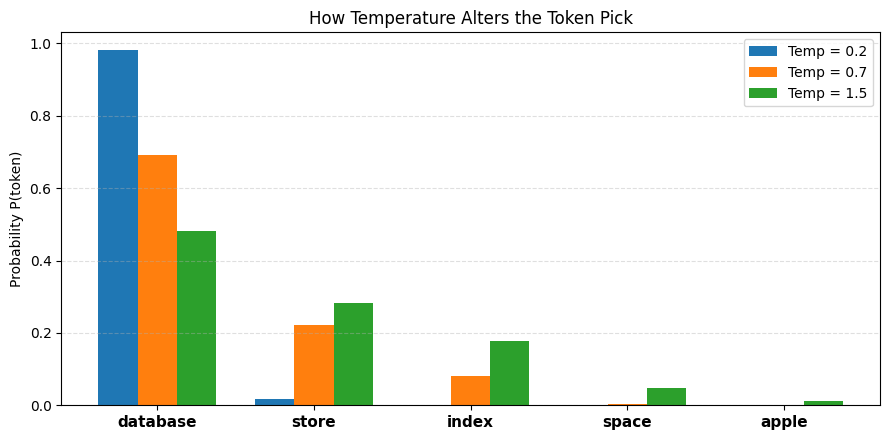

In [4]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Imagine the prompt is: "To store high-dimensional embeddings efficiently, use a vector ___"
# Here are candidate words and hypothetical raw logits from the model's final layer:
words = ["database", "store", "index", "space", "apple"]
logits = torch.tensor([6.0, 5.2, 4.5, 2.5, 0.5])

temps = [0.2, 0.7, 1.5]

plt.figure(figsize=(9, 4.5))
bar_width = 0.25
x = range(len(words))

for idx, T in enumerate(temps):
    # Scale logits by temperature and run softmax
    probs = F.softmax(logits / T, dim=-1).numpy()
    positions = [pos + (idx * bar_width) for pos in x]
    plt.bar(positions, probs, width=bar_width, label=f"Temp = {T}")

plt.xticks([pos + bar_width for pos in x], words, fontsize=11, fontweight="semibold")
plt.ylabel("Probability P(token)")
plt.title("How Temperature Alters the Token Pick")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Look at the chart above:
- At **Temp 0.2** (blue), `"database"` absorbs almost all probability mass. The model won't say anything else.
- At **Temp 1.5** (green), even `"space"` or `"apple"` have a nonzero shot at being selected.

---
## 3. Sampling: Top-K vs. Top-P (Nucleus)

Even with temperature, we don't want the model picking completely random garbage from the bottom 10,000 tokens of the vocabulary. That's where **Top-K** and **Top-P** cut in.

1. **Top-K:** *"Only consider the top $K$ most likely tokens. Ignore the rest."*
   - Simple, but rigid. If the top 2 tokens are 98% of the probability mass, Top-K=50 still keeps 48 irrelevant tokens in play.

2. **Top-P (Nucleus):** *"Keep adding the top tokens until their combined probability hits $P$ (e.g. 90%). Cut off everything else."*
   - Dynamic and adaptive. If the model is confident, it might only keep 1 or 2 tokens. If the context is open-ended, it expands the pool naturally.

In [5]:
def sample_top_p(logits, p=0.85, temp=0.7):
    scaled = logits / temp
    sorted_logits, sorted_indices = torch.sort(scaled, descending=True)
    sorted_probs = F.softmax(sorted_logits, dim=-1)
    cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

    # Mask out tokens beyond cumulative p
    remove_mask = cumulative_probs > p
    remove_mask[..., 1:] = remove_mask[..., :-1].clone()
    remove_mask[..., 0] = 0

    scaled_copy = scaled.clone()
    scaled_copy[sorted_indices[remove_mask]] = -float('inf')

    filtered_probs = F.softmax(scaled_copy, dim=-1)
    choice = torch.multinomial(filtered_probs, num_samples=1).item()
    return choice

print("Simulating 5 successive draws with Top-P = 0.85:")
for i in range(5):
    picked_idx = sample_top_p(logits, p=0.85, temp=0.7)
    print(f"  Run {i+1}: Picked '{words[picked_idx]}'")

Simulating 5 successive draws with Top-P = 0.85:
  Run 1: Picked 'database'
  Run 2: Picked 'database'
  Run 3: Picked 'database'
  Run 4: Picked 'store'
  Run 5: Picked 'database'


---
## 4. Context Windows & The "Lost in the Middle" Reality

Providers boast about 128k, 1M, or 2M token context windows. But in production engineering, **longer context does not equal better answers**.

Here's why:
1. **Primacy Effect:** The model pays heavy attention to instructions at the very beginning (system prompt).
2. **Recency Effect:** The model pays heavy attention to the text right at the end (the user's latest query).
3. **The Middle Dip ("Lost in the Middle"):** When you dump 50 pages into a prompt, facts buried in the middle 30%–70% have a much higher chance of being ignored or retrieved incorrectly.

**Why this connects to what I'm building:**  
This is the exact reason why **RAG (Retrieval-Augmented Generation)** exists! Instead of stuffing 100 pages into a prompt and praying the attention heads notice the right fact, we use our vector database (Qdrant / FAISS from Days 27–28) to pull the top 3 targeted chunks and feed *only* those into the context window.

---
## 5. My Summary for Day 29

Here is the core intuition boiled down into five clean sentences:

> 1. Large Language Models don't read words or characters; they ingest text split into statistical subword integer tokens via Byte-Pair Encoding (BPE).
> 2. At every step, the model computes an unnormalized score (logit) for every single token in its vocabulary to predict what comes next.
> 3. Softmax turns those raw logits into a valid probability distribution, and temperature controls whether the selection is laser-focused or exploratory.
> 4. Top-P (nucleus) sampling trims out the long tail of low-probability tokens dynamically to prevent bizarre or hallucinated outputs.
> 5. Because attention heads suffer from degradation in long prompts ("lost in the middle"), precision retrieval via vector databases is far more reliable and cost-effective than dumping massive context blindly.